# Métodos con base física

## Objetivos de aprendizaje

Al finalizar este capítulo, el estudiante será capaz de:

- Comprender el concepto de Factor de Seguridad (FS) y su aplicación en la estabilidad de laderas mediante el modelo de talud infinito.
- Interpretar los resultados del modelo SHALSTAB identificando las cuatro clases de estabilidad (incondicionalmente estable/inestable, condicionalmente estable/inestable).
- Describir el fundamento del modelo TRIGRS para análisis transitorios de infiltración y estabilidad.
- Analizar la sensibilidad del FS respecto a los parámetros geotécnicos (cohesión, ángulo de fricción, profundidad de falla).

**Duración estimada:** 3–4 horas

## Requisitos previos

- **Geotecnia:** criterio de falla de Mohr-Coulomb, presión de poros, parámetros de resistencia efectivos (c', φ').
- **Hidrogeología:** concepto de nivel freático, saturación del suelo.
- **Python:** `numpy`, `matplotlib`, `rasterio`.
- **Capítulos anteriores:** `06_variables` (mapas raster de pendiente, propiedades del suelo), `07_detonante` (lluvia como factor detonante).

Los modelos con base física evalúan la ocurrencia de movimientos en masa en términos de factor de seguridad o probabilidades de ocurrencia, a través de modelos numéricos. Sin embargo existen diferentes aproximaciones a la física del problema con simplificaciones diferentes, por lo cual es fundamental utilizar el modelo que se ajuste a las necesidades o particularidades del área de estudio. Los métodos con base física son recomendables para áreas pequeñas a escalas detalladas, ya que requieren una gran cantidad de información de entrada, que se obtiene de ensayos de laboratorio o mediciones de campo. Por lo que la parametrización de los modelos puede ser complicada, en especial la distribución espacial de la profundidad del suelo, la cual juega un papel fundamental. Los modelos con base física permiten tener en consideración la complejidad de los factores detonantes (sismo y/o lluvia) y las características geomecánicas del terreno. 

## Factor detonante lluvia

El componente hidrológico de estos modelos explica el proceso de infiltración del agua en el suelo y el avance del frente húmedo o aumento de un nivel freático colgado. Para esto utilizan modelos de flujo estático horizontal o modelos de flujo transitorio vertical. Desde el componente geotécnico, la mayoría de modelos utilizan métodos de equilibrio límite de talud infinito. Algunos han incorporado modelos de dovelas que permiten análisis de superficies de falla circulares.

Como parte de los modelos físicos una gran variedad de modelos hidrológicos se han utilizado considerando el flujo de agua en el suelo en estado estático o transitorio, y en condiciones saturadas o parcialmente saturadas, utilizando las ecuaciones de Richards para el flujo vertical y las ecuaciones de Darcy para el flujo lateral. Entre estos se encuentra TOPOG {cite:p}`o1986`, TAPES {cite:p}`moore1988`, TOPMODEL {cite:p}`beven1979`, GEOtop {cite:p}`bertoldi2006`, tRIBS {cite:p}`ivanov2004`, SHIA {cite:p}`velez2001`, y los modelos de Green-Ampt {cite:p}`greenampt1911`, Pradel & Raad {cite:p}`pradel1993` e Iverson {cite:p}`iverson2000`. Por el contrario, los modelos geotécnicos utilizados son muy similares, generalmente utilizando el método talud infinito y análisis de equilibrio límite, suponiendo la superficie de falla paralela a la superficie del terreno y que la longitud de falla es mucho mayor que el espesor de la capa desplazada {cite:p}`borga2002`.

:::{figure-md} hidrologico
<img src="https://i.pinimg.com/564x/52/32/4a/52324a660eca43147a3ad80d2da9f621.jpg" alt="modelo hidrologico" width="600px">

Dos posibles mecanismos de saturación para deslizamientos planares superficiales detonados por lluvias. Izquierda: incremento del nivel freático colgado paralelo a la ladera a partir de una superficie de contraste de permeabilidad. Derecha: avance de frente húmedo a partir de la superficie del terreno.
:::

Uno de los primeros modelos físicos fue propuesto por {cite:t}`wu1995` denominado dSLAM (distribuited Shallow LAndslide Model), y posteriormente modificado como IDSSM (Integrated Dynamic Slope Stability Model) por {cite:t}`dhakal2003`. Corresponde a un modelo físico, dinámico y distribuido, que utiliza un análisis de estabilidad de talud infinita con un modelo hidrológico de onda cinemática propuesto por {cite:t}`takasao1988`. Este modelo considera la vegetación y asume que la infiltración es siempre mayor a la intensidad de la lluvia.

Sin embargo uno de los modelos físicos más reconocido por su sencillez y fácil aplicación es el modelo propuesto por {cite:t}`montgomery1994` y {cite:t}`montgomery1998`, denominado SHAllow Landslide STABility (SHALSTAB). Este modelo emplea el modelo hidrológico TOPOG para estimar la altura de la porción saturada de suelo, el cual asume que el control dominante de la distribución espacial de los movimientos está dado por la topografía. Estos autores definen para su análisis un índice topográfico, el cual es utilizado para predecir el nivel freático en función del flujo del agua en el suelo y la intensidad de la lluvia. El modelo de estabilidad propuesto utiliza el criterio de Mohr-Coulomb, en el cual por simplificación asumen la cohesión igual cero. 

Otros modelos conceptualmente similares al SHALSTAB se han desarrollado. El modelo SINMAP, desarrollado por {cite:t}`pack1998`, evalúa las condiciones de estabilidad para movimientos en masa, utilizando la misma ecuación del factor de seguridad y las ecuaciones de Darcy para flujos saturados, pero a diferencia del SHALSTAB considera la cohesión del suelo. Y el modelo LISA (por sus siglas en inglés Level I Stability Analysis), desarrollado por {cite:t}`hammond1992`, realiza un análisis probabilístico basado en el factor de seguridad, considerando la vegetación. Los valores para cada parámetro en la ecuación son definidos por una función de distribución de probabilidades y los resultados son presentados en un histograma que muestra la distribución del factor de seguridad calculado usando el método de Monte Carlo.

El modelo GEOtop–FS, desarrollado por {cite:t}`simoni2008`, combina un análisis de estabilidad de talud infinito con el modelo hidrológico distribuido espacialmente y de diferencias finitas, GEOtop. El modelo estima el contenido de agua en el suelo y la evolución de la presión de poros resultante simulando los procesos de infiltración, escorrentía superficial, flujo subsuperficial saturado y no saturado, y flujos en canales. Para lo cual todas las celdas de la cuenca son divididas en celdas tipo canal y tipo laderas. El factor de seguridad se calcula con un enfoque probabilístico, donde los parámetros del suelo se asignan con funciones de distribución.

El modelo CHASM (Combined Hydrological And Stability Model), desarrollado por {cite:t}`wilkinson2000`, utiliza el método simplificado circular de {cite:t}`bishop1955` con un modelo hidrológico bidimensional de diferencias finitas para simular el cambio en las presiones de poros como respuesta a eventos de lluvia individuales. En cada intervalo de tiempo de simulación, las presiones de poro, tanto negativas como positivas, se incorporan directamente en la determinación de los esfuerzos efectivos y la resistencia al corte del suelo. Este análisis implica una búsqueda numérica de la superficie de deslizamiento que reduce al mínimo el factor de seguridad.

El modelo Transient Rainfall Infiltration and Gridbased Slope-Stability (TRIGRS), desarrollado por {cite:t}`baum2002`, utiliza el modelo hidrológico transitorio unidimensional para infiltración vertical propuesto por {cite:t}`iverson2000`, con un modelo de estabilidad de talud infinita asumiendo condiciones saturadas. El modelo evalúa el factor de seguridad como respuesta de las presiones de poros durante un evento de lluvia función de la profundidad y el tiempo, para lo cual divide el factor de seguridad en un componente estático (Fs0) asociados al estado estático o de largo plazo, y un componente que varía con el tiempo (FS)’ asociado al estado transitorio del evento de lluvia simulado.

{cite:t}`arnone2011` proponen un modelo físico distribuido, en el cual acoplan un modelo de talud infinita con el modelo hidrológico tRIBS (Triangulated Irregular Network Real-Time Integrated Basin Simulator) desarrollado por {cite:t}`ivanov2004`. El modelo simula la intercepción de la lluvia, la evapotranspiración, la infiltración del agua en el suelo, la escorrentía superficial, y el flujo subsuperficial lateral a la ladera en condiciones saturadas y parcialmente saturadas, representando la heterogeneidad espacial de la topografía por una red irregular triangular (TIN) utilizada ampliamente por Sistemas de Información Geográfica (SIG) que reduce el tiempo computacional sin pérdidas aparentes de información. El modelo es también capaz de simular el volumen del material fallado y su posible trayecto.

Finalmente el modelo SHIA_Landslide propuesto por {cite:t}`aristizabal2016` acopla un modelo de talud infinita en condiciones saturadas con el modelo hidrológico distribuido de tanques a escala de cuenca que considera los flujos verticales y horizontales, denominado SHIA {cite:p}`velez2001`. El modelo hidrológico está conformado por dos componentes: un balance de agua que simula los proceso hidrológicos dominantes en la cuenca, tales como infiltración, percolación, escorrentía superficial, flujo sub superficial, y flujo subterráneo; y un componente que simula el flujo del agua a través de la red de drenaje, lo que permite calibrar con valores observados la hidrología de la cuenca y las laderas previo a la simulación de estabilidad de las vertientes.

Un ejemplo de aplicación de estos modelos físicos en un contexto de riesgo, más allá de la simple susceptibilidad, corresponde al estudio de amenaza por movimientos en masa en el municipio de Copacabana (Valle de Aburrá), donde el modelo SHALSTAB fue implementado junto con modelos de vulnerabilidad física estructural (tipo T) para estimar el riesgo de las edificaciones expuestas, obteniendo valores ilustrativos de vulnerabilidad física estructural (VP-S) de 0,53 y un riesgo estimado de 1,2x10⁻¹ personas para una estructura tipo V1, lo cual evidencia cómo los resultados de los modelos físicos de estabilidad pueden acoplarse directamente con modelos de vulnerabilidad para completar la cadena de análisis de riesgo.

:::{figure-md} modelos
<img src="https://i.pinimg.com/564x/83/23/d3/8323d33e987c258078dd4d5e13d2f241.jpg" alt="modelos" width="500px">

modelos físicos.
:::

## Clasificación de los modelos con base física determinísticos

{cite:t}`sachinthaka2025` realizaron una revisión bibliométrica y sistemática de los Modelos Físicos Determinísticos para susceptibilidad de deslizamientos inducidos por lluvia (PBDMs, por sus siglas en inglés). A partir del análisis de 70 estudios identificados en Scopus, propusieron una clasificación en cuatro grupos o *clusters* basada en el enfoque hidrológico empleado (Fig. 6 y Fig. 7). La Fig. 6 muestra la frecuencia con que cada modelo ha sido utilizado en los estudios revisados, siendo TRIGRS el más aplicado, seguido de los modelos personalizados (*Custom*) y SINMAP.

### Tabla 2. Comparación de los cuatro grupos de modelos físicos determinísticos

| Característica | Cluster 1 – Estático / Simplificado | Cluster 2 – Transitorio (Richards) | Cluster 3 – Distribuido Multicapa | Cluster 4 – Acoplado / Híbrido |
|---|---|---|---|---|
| **Enfoque hidrológico** | Infiltración estacionaria o simplificada | Richards: infiltración transitoria variablemente saturada | Modelos distribuidos (multicapa o de tanques) | Módulos acoplados (múltiples) |
| **Dependencia temporal** | No | Sí | Sí | Varía (generalmente sí) |
| **Presión de poros** | Estática o basada en índice | Dinámica y variable en el tiempo | Dinámica, espacial y verticalmente variable | Dinámica, depende del módulo |
| **Estabilidad de ladera** | Talud infinito (LEM) | Talud infinito (LEM) | Talud infinito / FS local | Talud infinito / local / 3D / probabilístico |
| **Adaptabilidad al cambio climático** | Limitada | Limitada; algunas adaptaciones recientes | Moderada (dependiente de la calidad de datos) | Moderada a alta (basada en escenarios) |
| **Cuantificación de incertidumbre** | Raramente incluida | Versiones probabilísticas disponibles (TRIGRS-P) | Ocasionalmente aplicada | Frecuentemente incluida (híbridos probabilísticos) |
| **Eficiencia computacional** | Alta (rápida) | Moderada | Baja (computacionalmente exigente) | Baja (exigente) |
| **Demanda de datos de entrada** | Mínima (topografía y suelo básico) | Moderada-alta (propiedades hidráulicas del suelo) | Alta (datos espaciales/suelo de alta resolución) | Muy alta (múltiples fuentes de datos) |
| **Escala típica de aplicación** | Regional | Cuenca hidrográfica a sitio específico | Cuenca hidrográfica | Sitio específico o escenarios complejos |
| **Fortalezas clave** | Rápido, fácil de usar | Preciso para lluvias de corta duración | Captura flujos subsuperficiales complejos | Altamente adaptable, orientado a escenarios |
| **Limitaciones principales** | Sobre-simplificado, insensible a variaciones temporales | Intensivo en datos, mayor demanda computacional | Calibración difícil en zonas con datos escasos | Integración compleja, generalización reducida |

*Fuente: adaptado de Sachinthaka et al. (2025)*

### Cluster 1: modelos con hidrología en estado estático o simplificado

Los modelos del Cluster 1 asumen que la infiltración o el flujo de agua subterránea alcanza el equilibrio rápidamente y permanece constante en el tiempo. Esta simplificación reduce drásticamente las demandas computacionales y de datos, lo que los hace especialmente adecuados para aplicaciones a escala regional y en entornos con escasez de datos. Sin embargo, sacrifican precisión en la simulación de respuestas rápidas de presión de poros durante eventos de lluvia intensos o de corta duración.

Entre los modelos de este grupo se destacan:

- **SHALSTAB** {cite:p}`montgomery1994`: combina el modelo hidrológico TOPMODEL con análisis de talud infinito. Asume cohesión nula y lluvia estacionaria.
- **SINMAP** {cite:p}`pack1998`: usa las mismas ecuaciones de flujo saturado de Darcy pero incorpora la cohesión del suelo y formulación probabilística para cuantificar incertidumbre.
- **SLIDE / SLIDE-P** {cite:p}`luo2021,liao2012`: SLIDE correlaciona directamente la profundidad de lluvia con cambios en la cohesión aparente y la saturación. SLIDE-P extiende esto mediante simulaciones de Monte Carlo para gestionar la variabilidad paramétrica.
- **SLIP** {cite:p}`ono2014`: introduce una función de saturación dependiente del tiempo acumulado de lluvia, similar a SLIDE pero con representación más explícita de la variación temporal.
- **ALICE** {cite:p}`vandromme2020`: modelo del BRGM que permite trabajar con perfiles de ladera bidimensionales y abordar deslizamientos superficiales y profundos, aunque con supuestos hidrológicos simplificados.
- **FSLAM** {cite:p}`ma2023`: combina un modelo de flujo de agua subsuperficial paralelo a la ladera (estilo TOPMODEL) con infiltración vertical basada en el método SCS-CN.

### Cluster 2: modelos de infiltración transitoria mediante la ecuación de Richards

Los modelos del Cluster 2 simulan procesos de infiltración transitoria con saturación variable, usando formulaciones derivadas de la ecuación de Richards, que combina la ley de Darcy para flujo no saturado con la ecuación de continuidad. Son físicamente más realistas que los modelos estacionarios y ofrecen mayor precisión en la predicción de deslizamientos superficiales, especialmente durante eventos de lluvia intensa o de corta duración.

- **TRIGRS** {cite:p}`baum2002`: resuelve una forma linealizada y unidimensional de la ecuación de Richards para calcular la variación temporal de la presión de poros en función de la profundidad. Calcula el Factor de Seguridad en cada celda de la cuadrícula. Es el modelo más ampliamente utilizado en la literatura revisada.
- **TRIGRS-P** {cite:p}`sinarta2017,chen2019`: extensión probabilística de TRIGRS que usa simulaciones de Monte Carlo para cuantificar incertidumbre en los parámetros geotécnicos e hidrológicos (cohesión, ángulo de fricción, conductividad hidráulica saturada).
- **Modelo de Iverson** {cite:p}`iverson2000`: solución semi-analítica de la ecuación de Richards bajo condiciones iniciales saturadas y lluvia de corta duración. Base conceptual de TRIGRS. Introduce la "corrección de línea beta" para limitar presiones de poros irreales a profundidades pequeñas.
- **SUSHI** {cite:p}`capparelli2011`: usa un esquema de diferencias finitas bidimensional para resolver la ecuación de Richards en flujos saturados y no saturados. Simula flujo lateral, heterogeneidad del suelo y geometrías irregulares de ladera.
- **HIRESSS** {cite:p}`rossi2013`: aplica una solución analítica simplificada de la ecuación de Richards optimizada para cómputo de alto rendimiento. Integra simulaciones de Monte Carlo directamente en el núcleo del modelo para generar mapas probabilísticos de FS en tiempo casi real.
- **HISSM** {cite:p}`abdollahi2024`: modelo especialmente diseñado para analizar susceptibilidad post-incendio forestal, integrando procesos hidromecánicos, refuerzo de raíces y efectos de recuperación post-fuego.

### Cluster 3: modelos hidrológicos distribuidos y multicapa

Los modelos del Cluster 3 representan un avance significativo al incorporar procesos distribuidos de lluvia-escorrentía con esquemas de almacenamiento de humedad en múltiples capas del suelo. A diferencia de los modelos 1D de infiltración o de estado estacionario, simulan el movimiento vertical y lateral del agua en paisajes heterogéneos, ofreciendo una representación más realista de la acumulación de presión de poros.

- **SHIA_Landslide** {cite:p}`aristizabal2016`: acopla un análisis de talud infinito en condiciones saturadas con el modelo hidrológico distribuido de tanques SHIA {cite:p}`velez2001`, que opera a escala de cuenca. El sistema de tanques simula cinco componentes hidrológicos (intercepción, escorrentía superficial, almacenamiento gravitacional, flujo del acuífero y flujo en canal), discretizando el perfil del suelo en capas de suelo residual, saprolita y roca de caja con distintas conductividades hidráulicas. El modelo estima dinámicamente los niveles freáticos colgados y los compara con umbrales de saturación críticos.
- **NEWAGE-JGrass** {cite:p}`formetta2016`: integra modelos físicos simplificados pero distribuidos (M1 a M3) dentro del marco GIS JGrass. M1 (Estado Estacionario) asume equilibrio instantáneo; M2 (Flujo Transitorio) incorpora dinámica temporal de infiltración durante lluvias de alta intensidad; M3 (Enfoque Híbrido) combina movimiento estacionario del agua subterránea con infiltración superficial transitoria, equilibrando eficiencia computacional y precisión.

### Cluster 4: marcos acoplados o híbridos

Los marcos acoplados o híbridos del Cluster 4 integran módulos hidrológicos físicamente basados con análisis de estabilidad de laderas, permitiendo una simulación más completa de las interacciones dinámicas entre infiltración de lluvia, evolución de la presión de poros y falla de ladera.

- **YS-Slope** {cite:p}`kim2014`: acopla una formulación modificada de Green-Ampt con un modelo de flujo de agua subterránea bidimensional basado en la ley de Darcy. El módulo hidrológico captura la evolución temporal tanto del frente de humedecimiento como del nivel freático ascendente. Estas dinámicas se conectan a un modelo de talud infinito mejorado que incorpora succión mátrica, sobrecarga vegetal y refuerzo de raíces.
- **iCRESTRIGRS** {cite:p}`zhang2016`: integra el modelo distribuido CREST (que simula intercepción, infiltración, dinámica de humedad del suelo y enrutamiento de flujo) con TRIGRS. CREST calcula los procesos lluvia-escorrentía distribuidos espacialmente y su salida es utilizada por TRIGRS para calcular dinámicamente la presión de poros y los factores de seguridad en el tiempo y el espacio. Este marco demostró rendimiento superior al TRIGRS independiente en un caso de estudio del huracán Ivan en Carolina del Norte.
- **SCOOP3D** {cite:p}`tran2022,durmaz2023`: realiza análisis de equilibrio límite tridimensional usando superficies de deslizamiento esféricas. En marcos acoplados, TRIGRS simula la infiltración transitoria y SCOOP3D utiliza las superficies piezométricas resultantes para predicciones de estabilidad 3D, permitiendo modelar deslizamientos de múltiples etapas y regresivos.

### Modelo SHALSTAB
El modelo SHALSTAB, desarrollado por {cite:t}`montgomery1994`, emplea el modelo hidrológico TOPOG {cite:p}`o1986` en condiciones de lluvia estacionaria para construir un mapa del patrón de la humedad basado en el área aferente a cada punto, la pendiente y la transmisividad del suelo. En el modelo la humedad del suelo es calculada como:

$W=\frac{Qa}{bTsinθ}$

Donde $Q$ es la lluvia en condiciones estacionarias ($mm/d$), a es el área de drenaje ($m^2$), $b$ es la longitud de cada celda ($m$), $T$ es la transmisividad del suelo en condiciones saturadas ($m^2/$), $\theta$ y  es la pendiente. Asumiendo que la transmisividad no varía con la profundidad, se puede entonces asumir:

$W= \frac{h}{z_t}$ 				

Donde $h$ es el espesor del suelo saturado y $z_t$ el espesor total de suelo. Combinando las dos ecuaciones anteriores se puede estimar la saturación relativa del perfil de suelo como:

$\frac{h}{z_t}=\frac{Qa}{bTsinθ} 	$

En cuanto al componente geotécnico, el modelo SHALSTAB está basado en análisis de equilibrio límite con talud infinito y el criterio de falla de Mohr-Coulomb.

$ρ_sgz_tsinθcosθ=C'+[ρ_s-ρ_w\frac{h}{z_t}]gzcos^2θtanϕ 	$

Donde $ρ_s$ es la densidad del suelo, $ρw$ es la densidad del agua, $g$ es la aceleración de la gravedad, $C’$ es la cohesión efectiva del suelo, y $φ$ es el ángulo de fricción. Esta ecuación puede ser escrita en términos de la relación h/z como:

$\frac{h}{z_t}=\frac{ρ_s}{ρ_w}(1-\frac{tanθ}{tanϕ})+\frac{C'}{wgz_tcos^2θtanϕ}$

Finalmente acoplando el modelo hidrológico con el modelo de estabilidad se obtienen la siguiente ecuación:

$\frac{a}{b}=\frac{T}{Q}sinθ[\frac{ρ_s}{ρ_w}(1-\frac{tanθ}{tanϕ})+\frac{C'}{wgzcos^2θtanϕ}]$

A partir de esta ecuación es posible determinar cuatro condiciones de estabilidad para cada celda de análisis. Las celdas donde la relación entre el área de drenaje aferente y la longitud de la celda (a/b) es mayor que la expresión al lado derecho de la ecuación corresponde a celdas inestables, en caso contrario son celdas estables. Las dos condiciones restantes corresponden a condiciones de estabilidad que no dependen de la lluvia. Las celdas estables en condiciones completamente saturadas de todo el perfil de suelo ($h/z_t=1$) son denominadas incondicionalmente estables y cumplen la siguiente condición:

$tanθ < 1-(\frac{ρ_s}{ρ_w})tanϕ+\frac{C'}{ρ_sgz_tcos^2θ} $

Y las celdas inestables en condiciones secas ($h/z_t=0$) se denominan incondicionalmente inestables y cumplen la siguiente condición:

$tanθ >= tanϕ+\frac{C'}{ρ_sgz_tcos^2θ}$	

#### Python

A continuación se presenta el código en Python para implementar el modelo SHALSTAB. Para esto se debe contar con un mapa de cohesión [kN/m2], ángulo de fricción [radianes], conductividad hidráulica [cm/hora], peso unitario del suelo [kN/m3], área de drenaje acumulada [m2], pendiente [radianes] y espesor del suelo [m]. Estos mapas deben estar en formato raster y se importan con la librería *Rasterio*.  

Al inicio del código se requiere ajustar el valor que representa la resolución espacial de los mapas raster en metros. En este ejemplo se usan celdas con resolución 12,5 m. También se debe ajustar el valor de la lluvia estacionaria que se desea modelar en unidades de [mm/h]. En este ejemplo dicho valor es de 100 mm/h. Como resultado se obtienen tres (3) mapas. (i) El mapa **Matriz_estabilidad** con celdas estables (celdas con valor de 4), inestables (celdas con valor de 3), incondicionalmente inestables (celdas con valor de 2) e incondicionalmente estables (celdas con valor de 1). (ii) El mapa **Lluvia_critica**, que representa el valor de lluvia (q) necesario para que fallen las celdas. Este valor no aplica para celdas incondicionalmente inestables o incondicionalmente estables, solo para las celdas potencialmente inestables, es decir que arrojaron valores de 4 y 3 en el mapa de estabilidad. (iii) el mapa **volumen_inestable** que representa el volumen del material desplazado en cada celda.

### Factor de Seguridad: Modelo de Talud Infinito

El **Factor de Seguridad (FS)** es la razón entre las fuerzas resistentes y las fuerzas actuantes en una ladera. Es el criterio fundamental de todos los modelos físico-determinísticos (SHALSTAB, TRIGRS, SLOP/W).

Para suelos residuales poco profundos, el **modelo de talud infinito** es el punto de partida:

$$FS = \frac{c' + (\gamma_s - m\cdot\gamma_w)\cdot z\cdot\cos^2\beta\cdot\tan\phi'}{\gamma_s\cdot z\cdot\sin\beta\cdot\cos\beta}$$

donde:
- $c'$ = cohesión efectiva [kPa]
- $\phi'$ = ángulo de fricción interna efectivo [°]
- $\gamma_s$ = peso unitario del suelo [kN/m³]
- $\gamma_w$ = peso unitario del agua [kN/m³] = 9.81 kN/m³
- $z$ = profundidad del plano de falla [m]
- $\beta$ = ángulo de la pendiente [°]
- $m$ = relación altura capilar / profundidad (0 = seco, 1 = completamente saturado)

**Condición de falla:** $FS < 1.0$  
**Condición marginal:** $1.0 \leq FS < 1.5$  
**Condición estable:** $FS \geq 1.5$


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def factor_seguridad(c, phi_deg, gamma_s, z, beta_deg, m=1.0, gamma_w=9.81):
    """
    Factor de Seguridad — Modelo de Talud Infinito.

    Parámetros
    ----------
    c       : cohesión efectiva [kPa]
    phi_deg : ángulo de fricción efectivo [°]
    gamma_s : peso unitario del suelo [kN/m³]
    z       : profundidad del plano de falla [m]
    beta_deg: ángulo de pendiente [°]
    m       : grado de saturación (0=seco, 1=saturado)
    gamma_w : peso unitario del agua [kN/m³]

    Retorna
    -------
    float o ndarray — Factor de Seguridad
    """
    beta = np.radians(beta_deg)
    phi  = np.radians(phi_deg)
    resistencia = c + (gamma_s - m * gamma_w) * z * np.cos(beta)**2 * np.tan(phi)
    actuante    = gamma_s * z * np.sin(beta) * np.cos(beta)
    return resistencia / actuante

# ── Parámetros típicos de suelo residual andino ───────────────────────────────
c       = 5.0    # cohesión efectiva [kPa]
phi     = 28.0   # ángulo de fricción [°]
gamma_s = 18.0   # peso unitario del suelo [kN/m³]
z       = 2.0    # profundidad de falla [m]

pendientes = np.linspace(5, 60, 200)
FS_seco     = factor_seguridad(c, phi, gamma_s, z, pendientes, m=0.0)
FS_parcial  = factor_seguridad(c, phi, gamma_s, z, pendientes, m=0.5)
FS_saturado = factor_seguridad(c, phi, gamma_s, z, pendientes, m=1.0)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(pendientes, FS_seco,     'b-',  lw=2, label='Suelo seco (m = 0)')
ax.plot(pendientes, FS_parcial,  'g--', lw=2, label='Parcialmente saturado (m = 0.5)')
ax.plot(pendientes, FS_saturado, 'r-',  lw=2, label='Suelo saturado (m = 1)')
ax.axhline(1.0, color='k',      ls='--', lw=1.5, label='FS = 1 (falla)')
ax.axhline(1.5, color='orange', ls=':',  lw=1.5, label='FS = 1.5 (margen seguridad)')
ax.fill_between(pendientes, 0, 1, alpha=0.12, color='red')
ax.set_xlabel('Ángulo de pendiente β [°]', fontsize=12)
ax.set_ylabel('Factor de Seguridad (FS)', fontsize=12)
ax.set_title(
    'Factor de Seguridad — Modelo de Talud Infinito\n'
    f'c = {c} kPa,  φ = {phi}°,  γs = {gamma_s} kN/m³,  z = {z} m',
    fontsize=13
)
ax.legend(fontsize=10)
ax.set_ylim(0, 6)
ax.set_xlim(5, 60)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ── Mapa de FS para rangos de pendiente ──────────────────────────────────────
print('\nTabla de FS por rango de pendiente (suelo saturado):')
print(f'{'Pendiente (°)':<18} {'FS':<10} {'Condición'}')
print('-' * 40)
for beta in [10, 15, 20, 25, 30, 35, 40]:
    fs = factor_seguridad(c, phi, gamma_s, z, beta, m=1.0)
    cond = 'FALLA' if fs < 1 else ('Marginal' if fs < 1.5 else 'Estable')
    print(f'{beta:<18} {fs:<10.2f} {cond}')


C:\Users\edier\AppData\Local\Temp\ipykernel_25124\2575485777.py:134: RuntimeWarning: divide by zero encountered in divide
  q_crit_m_hr = (transmisividad * np.sin(pendiente) / ratio_hidrologico) * termino_geotecnico


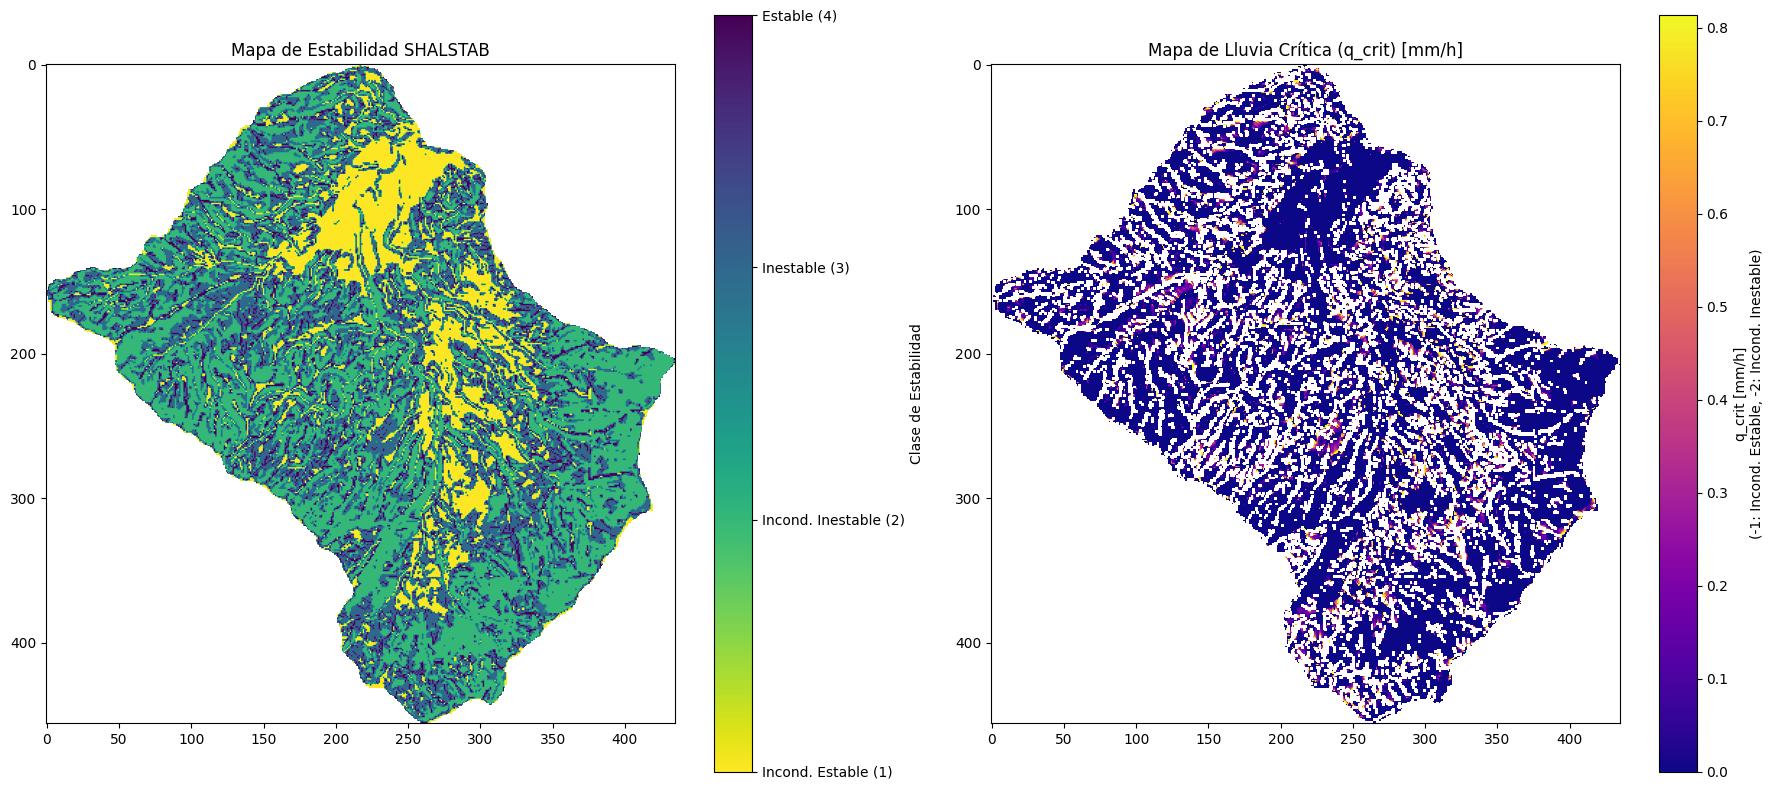

Análisis completado. Se han generado los archivos 'Matriz_Estabilidad.tif', 'Lluvia_Critica.tif' y 'Volumen_Inestable.tif'.


In [1]:
import rasterio as rio
import numpy as np
import matplotlib.pyplot as plt

# --- CODIFICACIÓN DEL MAPA DE SUSCEPTIBILIDAD ---
# El resultado principal es un mapa de estabilidad (o susceptibilidad a deslizamientos)
# donde cada celda se clasifica en una de cuatro categorías:
#
# 1: Incondicionalmente Estable: Zonas que son estables incluso en las condiciones más
#    desfavorables (suelo completamente saturado). No se espera que fallen.
# 2: Incondicionalmente Inestable: Zonas que son inestables incluso en condiciones secas.
#    La topografía y las propiedades del suelo por sí solas son suficientes para
#    causar la falla. Son las zonas más críticas.
# 3: Inestable: Zonas que son estables en condiciones secas pero se vuelven inestables
#    bajo la lluvia estacionaria definida (Q). La inestabilidad depende de la lluvia.
# 4: Estable: Zonas que permanecen estables bajo la lluvia estacionaria definida (Q).
#
# --- CODIFICACIÓN DEL MAPA DE LLUVIA CRÍTICA (q_crit) ---
# Este mapa muestra la intensidad de lluvia mínima (en mm/h) necesaria para que una
# celda condicionalmente estable se vuelva inestable.
#
# - Valores > 0: Representan la intensidad de lluvia crítica (q_crit) en mm/h.
# - Valor = -1: Corresponde a las zonas "Incondicionalmente Estables". Teóricamente,
#   ninguna cantidad de lluvia las haría fallar bajo los supuestos del modelo.
# - Valor = -2: Corresponde a las zonas "Incondicionalmente Inestables". Estas zonas
#   fallan incluso sin lluvia, por lo que el concepto de "lluvia crítica" no aplica.

# --- 1. Definición de Constantes y Parámetros ---

PESO_UNITARIO_AGUA = 9.81  # Peso unitario del agua (gamma_w) en [kN/m3]
RESOLUCION_CELDA = 12.5     # Resolución espacial del raster (dx o b) en [m]
LLUVIA_ESTACIONARIA = 100.0 # Intensidad de la precipitación (Q) en [mm/h]

# --- 2. Carga de Datos Raster ---
# Se cargan todos los datos geoespaciales necesarios para el modelo.
# Los datos se leen y se manejan los valores Nodata.

def cargar_raster(url):
    """
    Función auxiliar para abrir un raster desde una URL, leer la primera banda
    y manejar los valores NoData. Asume que el valor NoData es el de la esquina
    superior izquierda, lo cual es común en archivos .asc.
    """
    with rio.open(url) as raster:
        # Guardamos la información de proyección y transformación para los archivos de salida
        transform = raster.transform
        crs = raster.crs
        nodata_value = raster.nodata
        
        datos = raster.read(1)
        
        # Una forma más robusta de manejar NoData si está definido en el metadato
        if nodata_value is not None:
            datos = np.where(datos == nodata_value, np.nan, datos)
        else:
            datos = np.where(datos == datos[0, 0], np.nan, datos)
            
        return datos, transform, crs

# URLs de los datos de entrada
url_cohesion = 'https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/Arenosa/cohesion.asc'
url_friccion = 'https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/Arenosa/friction_rad.asc'
url_ks = 'https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/Arenosa/ks.asc'
url_peso_suelo = 'https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/Arenosa/gammas.asc'
url_acum_flujo = 'https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/Arenosa/flowacum_m2.asc'
url_pendiente = 'https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/Arenosa/slope_rad.asc'
url_espesor = 'https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/Arenosa/zs.asc'

# Carga de los datos
cohesion, transform, crs = cargar_raster(url_cohesion) # C' [kN/m2]
angulo_friccion, _, _ = cargar_raster(url_friccion) # phi [radianes]
ks, _, _ = cargar_raster(url_ks) # Conductividad hidráulica [cm/hora]
peso_unitario_suelo, _, _ = cargar_raster(url_peso_suelo) # gamma_s [kN/m3]
area_drenaje, _, _ = cargar_raster(url_acum_flujo) # a [m2]
pendiente, _, _ = cargar_raster(url_pendiente) # theta [radianes]
espesor_suelo, _, _ = cargar_raster(url_espesor) # z_t [m]

# --- 3. Conversión de Unidades ---
# Aseguramos que todas las unidades sean consistentes (metros, horas, kN)

# Convertir ks de cm/hora a m/hora
ks_m_hr = ks * 0.01
# Convertir lluvia de mm/hora a m/hora
q_m_hr = LLUVIA_ESTACIONARIA * 0.001

# --- 4. Análisis de Estabilidad SHALSTAB ---
# Se implementan las ecuaciones del modelo para clasificar la estabilidad de cada celda.

# Inicializar la matriz de estabilidad. Usamos np.nan para un fondo "vacío".
matriz_estabilidad = np.full(cohesion.shape, np.nan)

# Términos comunes para simplificar las ecuaciones
tan_pendiente = np.tan(pendiente)
tan_friccion = np.tan(angulo_friccion)
cos2_pendiente = np.cos(pendiente)**2

# --- Condición 1: Incondicionalmente Inestable (Seco) ---
# tan(θ) >= tan(φ) + C' / (γ_s * z_t * cos²(θ))
condicion_inestable_seco = tan_friccion + (cohesion / (peso_unitario_suelo * espesor_suelo * cos2_pendiente))
matriz_estabilidad = np.where(tan_pendiente >= condicion_inestable_seco, 2, matriz_estabilidad)

# --- Condición 2: Incondicionalmente Estable (Saturado) ---
# tan(θ) < (1 - γ_w/γ_s) * tan(φ) + C' / (γ_s * z_t * cos²(θ))
condicion_estable_saturado = (1 - (PESO_UNITARIO_AGUA / peso_unitario_suelo)) * tan_friccion + (cohesion / (peso_unitario_suelo * espesor_suelo * cos2_pendiente))
matriz_estabilidad = np.where(tan_pendiente < condicion_estable_saturado, 1, matriz_estabilidad)

# --- Condición 3 y 4: Estabilidad Condicional (Dependiente de la Lluvia) ---
# Se evalúan las celdas que no cayeron en las categorías anteriores (donde la matriz aún es NaN).

# Lado izquierdo de la ecuación acoplada: a/b
ratio_hidrologico = area_drenaje / RESOLUCION_CELDA

# Lado derecho de la ecuación acoplada: (T/Q) * sin(θ) * [Término Geotécnico]
# Transmisividad (T) = ks * z_t (asumiendo flujo paralelo a la superficie)
transmisividad = ks_m_hr * espesor_suelo
# Término geotécnico que representa la resistencia del suelo
termino_geotecnico = ((peso_unitario_suelo / PESO_UNITARIO_AGUA) * (1 - tan_pendiente / tan_friccion) + 
                      (cohesion / (PESO_UNITARIO_AGUA * espesor_suelo * cos2_pendiente * tan_friccion)))

# Lado derecho completo
ratio_estabilidad = (transmisividad / q_m_hr) * np.sin(pendiente) * termino_geotecnico

# Aplicar condiciones solo donde la matriz_estabilidad es todavía NaN
# Inestable: a/b > ratio_estabilidad
matriz_estabilidad = np.where(np.logical_and(np.isnan(matriz_estabilidad), ratio_hidrologico > ratio_estabilidad), 3, matriz_estabilidad)
# Estable: a/b <= ratio_estabilidad
matriz_estabilidad = np.where(np.logical_and(np.isnan(matriz_estabilidad), ratio_hidrologico <= ratio_estabilidad), 4, matriz_estabilidad)

# --- 5. Cálculo de la Lluvia Crítica (q_crit) ---
# Se calcula la intensidad de lluvia necesaria para causar la inestabilidad.

# Reorganizando la ecuación acoplada para resolver para Q (q_crit):
# q_crit = (T * sin(θ) / (a/b)) * [Término Geotécnico]
q_crit_m_hr = (transmisividad * np.sin(pendiente) / ratio_hidrologico) * termino_geotecnico

# Convertir q_crit a mm/h para una interpretación más fácil
q_crit_mm_hr = q_crit_m_hr * 1000

# Limpiar valores infinitos que pueden surgir de divisiones por cero (ej. en zonas planas)
q_crit_mm_hr[q_crit_mm_hr == np.inf] = np.nan

# Asignar códigos especiales a las zonas incondicionales en el mapa de lluvia crítica
# -1 para incondicionalmente estable
# -2 para incondicionalmente inestable
mapa_q_critica = np.where(matriz_estabilidad == 1, -1, q_crit_mm_hr)
mapa_q_critica = np.where(matriz_estabilidad == 2, -2, mapa_q_critica)


# --- 6. Visualización de Resultados ---
plt.figure(figsize=(18, 8))

# Mapa de Estabilidad
plt.subplot(1, 2, 1)
im1 = plt.imshow(matriz_estabilidad, cmap='viridis_r')
plt.title('Mapa de Estabilidad SHALSTAB')
plt.colorbar(im1, ticks=[1, 2, 3, 4], label="Clase de Estabilidad").ax.set_yticklabels(['Incond. Estable (1)', 'Incond. Inestable (2)', 'Inestable (3)', 'Estable (4)'])

# Mapa de Lluvia Crítica
plt.subplot(1, 2, 2)
im2 = plt.imshow(mapa_q_critica, cmap='plasma', vmin=0, vmax=np.nanpercentile(mapa_q_critica, 95)) # vmax al percentil 95 para mejor visualización
plt.title('Mapa de Lluvia Crítica (q_crit) [mm/h]')
plt.colorbar(im2, label="q_crit [mm/h]\n(-1: Incond. Estable, -2: Incond. Inestable)")

plt.tight_layout()
plt.show()


# --- 7. Exportación de Resultados ---
# Guardar los resultados como archivos GeoTIFF, preservando el sistema de coordenadas.

def guardar_geotiff(nombre_archivo, datos, transform, crs):
    """Función auxiliar para guardar un array de numpy como un GeoTIFF."""
    with rio.open(
        nombre_archivo, 'w',
        driver='Gtiff',
        height=datos.shape[0],
        width=datos.shape[1],
        count=1,
        dtype=datos.dtype,
        nodata=np.nan, # Usar NaN como valor NoData
        crs=crs,
        transform=transform
    ) as dst:
        dst.write(datos, 1)

# Guardar mapa de estabilidad
guardar_geotiff('Matriz_Estabilidad.tif', matriz_estabilidad, transform, crs)

# Guardar mapa de lluvia crítica
guardar_geotiff('Lluvia_Critica.tif', mapa_q_critica, transform, crs)

# Calcular y guardar el volumen de suelo potencialmente inestable
volumen_inestable = np.where(np.logical_or(matriz_estabilidad == 2, matriz_estabilidad == 3), 
                             espesor_suelo * (RESOLUCION_CELDA**2), 0)
volumen_inestable = np.where(np.isnan(matriz_estabilidad), np.nan, volumen_inestable) # Propagar NaNs
guardar_geotiff('Volumen_Inestable.tif', volumen_inestable, transform, crs)

print("Análisis completado. Se han generado los archivos 'Matriz_Estabilidad.tif', 'Lluvia_Critica.tif' y 'Volumen_Inestable.tif'.")


El modelo SHALSTAB también es posible implementarlo mediante los sistemas de información geográfica SAGA o GRASS SIG.

Para el caso de SAGA, la herramienta *Shalstab* se encuentra dentro de la caja de herramientas denominada *Terrain Analysis - Morphometry*. Como parámetros de entrada requiere:

* *Slope grid (rad)* un mapa raster de pendientes en radianes.
* *Catchment area grid (m2)*. Un mapa de área acumulada en m2.
* *Min Density grid (g/cm3) y *Max Density grid (g/cm3)*. Mapas opcionales del peso mínimo y máximo unitario del suelo. 
* *Min Hydraulic conductivity grid (m/hr) y *Max Hydraulic conductivity grid (m/hr)*. Mapas opcionales del valor de conductividad hidráulica mínima y máxima del suelo.
* *Min Thickness grid (m) y *Max Thickness grid (m)*. Mapas opcionales del espesor mínimo y máximo del suelo. 
* *Min Friction angle grid (degree) y *Max Friction angle grid (degree)*. Mapas opcionales del valor del ángulo de fricción mínimo y máximo del suelo. 
* *Min Bulk cohesion grid (MPa) y *Max Bulk cohesion grid (MPa)*. Mapas opcionales del valor de cohesión mínimo y máximo del suelo.
* *Min Friction angle grid (degree) y *Max Friction angle grid (degree)*. Mapas opcionales del valor del ángulo de fricción mínimo y máximo del suelo. 
* Valores globales mínimos y máximos de densidad del suelo, conductividad, espesor, ángulo de fricción, cohesión y un parámetro de corridas del modelo.

El modelo arroja como resultados el mapa tipo raster con los valores críticos de lluvia que genera la falla en cada celda, así como los valores de lluvia críticos utilizados para reclasificar el mapa.

La herramienta SHALSTAB de SAGA trabaja con los mapas grid si los proporcionas; si dejas los campos de los mapas grid vacíos, entonces utilizará los valores globales que definas. Esta dualidad ofrece flexibilidad: puedes realizar un análisis rápido con valores constantes o un análisis detallado con datos espacialmente variables.

La razón por la que SAGA pide un rango (mínimo y máximo), tanto para los mapas grid como para los valores globales, es para poder realizar un análisis de incertidumbre o de tipo probabilístico. Cuando se ejecuta el modelo, en lugar de usar un solo valor, SAGA puede tomar un valor aleatorio dentro del rango que le has proporcionado (entre el mínimo y el máximo) para cada celda. Esto permite simular la variabilidad natural de las propiedades del suelo. Si quieres un análisis determinista (no aleatorio), simplemente introduce el mismo mapa o el mismo valor tanto en el campo de mínimo como en el de máximo. Para un resultado rápido y determinista se deja el valor de *Parameter sampling runs* en 1. Para un análisis de riesgo más robusto y probabilístico se debe usar un número más alto, como 100. en este caso el mapa de salida no muestra el resultado de una sola simulación. En su lugar, da un resultado estadístico que resume todas las corridas. Un valor en una celda de 0.8 significaría que la celda falló en el 80% de las simulaciones.

Para el caso de GRASS SIG, *r.shalstab* no es un comando que venga instalado por defecto en GRASS. Es un "add-on" o una extensión que se debe instalar por separado. Por lo cual hay que abrir la terminal de GRASS (la que se inicia cuando se abre el programa) y usar:
```
g.extension extension=r.shalstab
```
Una vez que se instale puedes verificar con:
```
r.shalstab --help
```
Para correr el modelo, se necesitan dos cosas:

* **Un Modelo de Elevación Digital (DEM)**.

* **Parámetros del suelo**: es posible utilizar valores únicos y constantes para toda el área.

  - Densidad del suelo ($\rho_s$) en $kg/m³$.
  - Ángulo de fricción interna ($\phi$) en grados.
  - Cohesión del suelo ($c$) en ($N/m^2$). 
  - Profundidad del suelo ($z$) en m.
  - Conductividad hidráulica ($k$) en $m/h$.

Para importar el DEM puedes usar 
```
r.in.gdal input="C:/ruta/a/tu/dem.tif" output=dem
```
Y para establecer el mapaset:
```
g.region raster=dem
```
Ya con esto se puede correr el modelo con valores constantes de la siguiente forma:
```
r.shalstab elevation=dem density=1800 friction=35 cohesion=500 transmissivity=0.001 output=shalstab_mapa
```
Puedes consultar los mapas generados con el siguiente comando:
```
g.list type=raster
```
Para correr con los mapas de cada variable es solo reemplazar el valor de cada parámetro por el nombre del mapa.
```
r.shalstab.py dem=dem gamma=mapa_densidad phy=mapa_friccion c_soil=mapa_cohesion z=mapa_grosor k=mapa_conductividad susceptibility=susceptibilidad_variable critic_rain=lluvia_critica_variable
```

### Modelo TRIGRS
El modelo TRIGRS (Transient Rainfall Infiltration and Gridbased Slope-Stability) incorpora en su análisis el proceso de infiltración del agua lluvia y el cálculo del factor de seguridad. Este es un modelo con base física que evalúa la distribución temporal y espacial de movimientos en masa superficiales detonados por lluvia a través del cálculo de los cambios transitorios de la presión de poros y su incidencia en la variación del factor de seguridad, debido a la infiltración de la lluvia. 

:::{figure-md} TRIGRS
<img src="https://i.pinimg.com/564x/a3/c5/84/a3c584d944d2f76dc92ddebe309c571e.jpg" alt="TRIGRS" width="600px">

Modelo TRIGRS.
:::

El modelo de infiltración está basado en la solución lineal de las ecuaciones de Richards, y el flujo de 
agua en el suelo es el resultado de la sumatoria del estado estacionario y el componente transitorio asociado al evento de 
lluvia modelado. La solución para el caso de frontera basal impermeable a una profundidad finita está dada por:


Donde 𝜓 es la cabeza de presión, 𝑡 el tiempo. 

$𝑍 = 𝑧/𝑐𝑜𝑠 𝛿$

Donde 𝑍 es la coordenada en dirección vertical (positiva hacia abajo), $𝑧$ la coordenada en dirección normal al talud y $δ$ es el ángulo del terreno con la horizontal; $𝑑$ es la profundidad inicial del nivel en 
dirección vertical. 

$𝐵 = 𝑐𝑜𝑠2𝛿 − \frac{𝐼𝑍𝐿𝑇}{𝐾_𝑠}$

Donde $𝐾_𝑠$ es la conductividad hidráulica saturada en dirección $𝑍$, $𝐼𝑍𝐿𝑇$ la tasa de infiltración estacionaria (inicial) en la superficie del suelo. 𝐼𝑛𝑍 es la tasa de infiltración a una intensidad dada para el n-ésimo intervalo de tiempo. 

$𝐷1 = \frac{𝐷_0}{𝑐𝑜𝑠2𝛿}$

Donde $𝐷_0$ es la difusividad hidráulica saturada ($𝐷0 = \frac{𝐾_𝑠}{𝑆_𝑠}$, donde $𝑆_𝑠$ es el almacenamiento especifico). 𝑁 es el número total de intervalos y $𝐻(𝑡 − 𝑡_𝑛)$ es la función de paso de Heaviside, donde $𝑡_𝑛$ es el tiempo en el n-ésimo intervalo en la secuencia de infiltración de lluvia. La función $𝑖𝑒𝑟𝑓𝑐$ tiene la forma $𝑖𝑒𝑟𝑐𝑓 (𝜂) = 1√𝜋exp(−𝜂2) − 𝜂 𝑒𝑟𝑓𝑐 (𝜂)$, donde $𝑒𝑟𝑓𝑐(𝜂)$ es la función de error complementario.

Para estimar los cambios en el factor de seguridad como función de la profundidad ($Z$) y el tiempo ($t$) se utiliza el modelo de estabilidad de talud infinito de acuerdo con la siguiente ecuación: 

$FS(Z,t)=\frac{tan}{tanδ}+\frac{c'-ψ(Z,t)𝛾_𝑤tanϕ'}{𝛾_sZsenδcosδ}$

Donde $𝑐′$ es la cohesión efectiva del suelo, $𝜙′$ el ángulo de fricción efectivo, $𝛾𝑤$ el peso unitario del agua, $𝛾_𝑠$ el peso unitario 
del suelo y $𝜓(𝑍,𝑡)$ la cabeza de presión en función de la profundidad y el tiempo $𝑡$.

:::{figure-md} TRGRS
<img src="https://i.pinimg.com/564x/0f/25/52/0f255226c8b09d758217e86a2abbbdeb.jpg" alt="modelos" width="400px">

Modelo TRIGRS.
:::

#### Tutorial
*Elaborado por María Isabel Arango*.

Ingrese a la página web [TRIGRS](https://pubs.usgs.gov/of/2008/1159/downloads/) y descargue TRIGRS de acuerdo a su sistema operativo. Descomprima el archivo .zip y ábralo. Adicionalmente, puede descargar el [manual del usuario](https://pubs.usgs.gov/of/2008/1159/downloads/pdf/OF08-1159.pdf) donde encontrará toda la base teórica detrás del modelo, ilustraciones y un tutorial.

Como verá, la carpeta TRIGRS contiene varias subcarpetas y archivos en formato *txt*. TRIGRS y sus programas complementarios (TopoIndex, GridMatch y UnitConvert) no funcionan con una interfaz, sino que se ejecutan en ventanas de entrada y salida simples. Cada programa funciona a través de un ejecutable (*exe*), los cuales están ubicados en la subcarpeta *bin*. A su vez, cada ejecutable utiliza un archivo de inicialización que contiene los datos básicos necesarios para ejecutar el programa, así como los nombres de otros archivos de entrada.

En este taller, se trabajará sobre una zona de estudio ubicada en el municipio de San Carlos (Antioquia-Colombia) correspondiente a una parte de la cuenca de la quebrada La Arenosa, donde el 21 de septiembre de 1990 se presentó un evento de lluvia extremo que causó cientos de deslizamientos, muchos de los cuales alcanzaron los cauces y causaron una avenida torrencial. En este tutorial se implementará el modelo TRIGRS para identificar las zonas inestables usando los parámetros de la zona de estudio y bajo el escenario de precipitación del 21 de septiembre de 1990. La información requerida para llevar a cabo el análisis de estabilidad con TRIGRS incluye:

* Modelo de elevación digital (DEM)
* Mapa de pendientes
* Mapa de dirección de flujo
* Mapa de profundidad del suelo
* Propiedades mecánicas e hidrológicas del suelo. En caso de tener varias zonas con propiedades homogéneas, mapa de zonificación del suelo
* Escenario de precipitación. En caso de ser una precipitación heterogénea espacialmente, mapa espacialisado de las intensidades.

En todos los casos, los mapas que se utilicen deben ser de tipo raster en formato ASCII y deben cumplir con los siguientes criterios:

* Deben estar en el mismo sistema de coordenadas
* Deben tener las mismas dimensiones 
* Deben estar unidades metro-kilogramo-segundo

##### Preparación de los mapas

En la carpeta [Mapas Base](https://github.com/edieraristizabal/CartografiaGeotecnica/tree/master/libro/data/arenosa), encontrará los siguientes archivos raster. Para descargar los archivos selecciónelo, cuando Github visualice dicho archivo en la parte superior derecha seleccione *Raw* y con el botón derecho *Save as...*. Guárdelos como archivos ASCII eliminando la terminación *txt* que sale por defecto.

* dem_arenosa_clip: modelo de elevación digital 
* pendiente_arenosa_clip: pendiente en grados
* flowdir_arenosa_clip: dirección de flujo en formato ESRI
* profsuelo_arenosa_clip: mapa con la profundidad del suelo en metros

:::{figure-md} direccion
<img src="https://www.researchgate.net/publication/307632379/figure/fig6/AS:404373080428547@1473421463384/D8-ESRI-direction-code-overview.png" alt="direccion" width="400px">

Códigos usados por ESRI para la dirección de flujo
Profsuelo_Arenosa_Clip: Profundidad del suelo, en metros de la zona de estudio.
Suelos_Arenosa_Clip: Zonificación de los tipos de suelo presentes en la zona de estudio.
:::

Busque el archivo *dem_arenosa_clip.asc* y ábralo directamente desde el explorador para verlo en el editor de texto. Las primeras 6 líneas forman parte de la información base con la que cuenta todo archivo ASCII: número de columnas, de filas, coordenadas de la primera columna, coordenadas de la primera fila, tamaño de celda y valor para los datos nulos. Todos los archivos tipo ASCII que le ingrese a los archivos ejecutables deben tener valores idénticos de estos parámetros, de lo contrario genera error. Abra los archivos *pendiente_arenosa_clip*, *flowdir_arenosa_clip* y *profsuelo_arenosa_clip*, y compruebe que los parámetros de todos los archivos sean idénticos.

En GIS abra el raster *suelos_arenosa_clip.tif*. Explore en la tabla de atributos a cuáles unidades de suelo corresponden las categorías. Ahora, es necesario reclasificar el raster para que el modelo lo entienda, asignándole a cada unidad de suelo un número. 
En caso de utilizar *ArcToolbox*, vaya a *Spatial Analysis > Reclass > Reclassify*. En el campo *Input raster* agregue el raster de suelos, en el campo *Reclass Field* seleccione *Simb_Sue*, y reclasifique el raster de la siguiente forma. Guárdelo.

Tabla 1. Codificación de los tipos de suelo.

|Valores Antiguos|Valores Nuevos|
|------|-----|
|POc1 (Aluviales)|1|
|YAe1 (Suelo Residual)|2|
|YAf2 (Suelo residual)|2|
|NoData|NoData|


De esta forma, las unidades de suelo quedan divididas en dos categorías: depósitos aluviales (1) y suelos residuales del Batolito Antioqueño (2). Cada una de estas unidades tiene unas propiedades mecánicas e hidrológicas homogéneas.

Convierta el raster reclasificado a formato ASCII (*Conversion Tools > From Raster > Raster to ASCII*). Guárdelo con el nombre *suelos_arenosa_reclass_clip.asc*. Ábralo con el editor de texto y revise que los parámetros coincidan con los del resto de mapas.


##### Ejecución de los programas

Una vez tenga lista la información de entrada, debe ejecutar los programas auxiliares y finalmente TRIGRS, que se encuentran en la carpeta *bin*. Los programas auxiliares tienen como objetivo preparar la información ingresada y crear capas intermedias que son necesarias para el cálculo final. Estos programas deben ejecutarse siempre en el siguiente orden, ya que normalmente, los archivos de salida de uno son los archivos de entrada del siguiente.

* Unit Converter (Opcional): En caso de tener archivos en unidades distintas a las aceptadas por el modelo, este programa permite convertirlas (pfs a Pa, pies a metros, etc).
* Grid Match: Permite corroborar que todos los archivos ASCII contienen raster con el mismo número de celdas, coordenadas y tamaño de celda.
* Topo Index: Utiliza el DEM y la dirección de flujo para definir el patrón de distribución del flujo, calcular los factores de ponderación para distribuir la escorrentía de la superficie y calcular los tamaños de la matriz que utilizará TRIGRS para sus cálculos.
* TRIGRS: Una vez preparados los mapas y generado las capas intermedias, se corre el ejecutable final que realiza los cálculos de presión de poros y factor de seguridad para los instantes de tiempo que usted determine.

Cada ejecutable que se encuentra en la carpeta *bin* contiene un código que se ejecuta cada vez que se da doble click sobre el archivo *.exe*. Estos códigos necesitan para su correcto funcionamiento un archivo de entrada, el cual contiene los parámetros con los que debe correr el código, y es el archivo que usted como usuario debe modificar. Los archivos de entrada los encuentra en la carpeta TRIGRS con los siguientes nombres:

* uc_in.txt. archivo de inicio del Unit Coverter
* gm_in.txt. Archivo de inicio del Grid Match
* tpx_in.txt. archivo de inicio de Topo Index
* tr_in.txt. Archivo de inicio de TRIGRS

Cada vez  que se ejecuta los *.exe*, este buscará su archivo de inicio en la misma carpeta donde está el archivo *.exe*. Por lo tanto, organice todos los archivos de inicio de la carpeta TRIGRS en la misma carpeta con los archivos *.exe*. Trate de conservar los archivos de inicio originales en la carpeta TRIGRS siempre, ya que le serán de utilidad para detectar errores en el archivo que está editando. También, evite cambiar los nombres de los archivos de inicio, ya que esto genera fácilmente errores.

Dado que toda la información está en formato metro-kilogramo-segundo, no se ejecutará *Unit Converter*. Siga los siguientes pasos para ejecutar el resto de programas:



##### Grid Match

Grid Match permite asegurarse que todos los archivos tipo ASCII con los que trabajará tienen las mismas dimensiones y no tienen condiciones que generen error. Estas condiciones incluyen también que un mapa tenga una celda nula en la misma ubicación donde otros mapas tienen información.
* Abra el archivo *gm_in.txt*. Los archivos de entrada tienen un formato de fácil interacción, donde cada parámetro está explicado en su parte superior. Los archivos ya vienen con información cargada a modo de ejemplo, así que usted debe modificar los parámetros según su caso de estudio. También debe separar con comas los parámetros tal cual están separadas sus explicaciones. (Por ejemplo, fíjese en la línea 3 que dice: rows, columns. Eso significa que en la línea 4 usted debe reemplazar el 10, 10 por las dimensiones del DEM con el que trabajará, con el número de filas separado por una coma del número de columnas. Los espacios son indiferentes, la coma designa la separación entre dos parámetros, y el punto es el separador de decimales).
* En la línea 2, escriba el número de mapas que desea corroborar. En nuestro caso son 5 (DEM, pendiente, dirección de flujo, profundidad del suelo y tipos de suelo). 
* En la línea 4, escriba las dimensiones de los mapas que va a ingresar. Lea estos valores en cualquiera de los archivos ASCII de entrada como *nrows* y *ncols*. 
* En las líneas 6 en adelante, usted debe enumerar uno por uno los archivos ASCII que desea corroborar con su ruta de acceso y cada uno en una línea. Ingrese primero el DEM.
* Para este ejercicio, seguirá la opción más simple de ingreso de los archivos. Para esto, copie y pegue los archivos ASCII de información base (*dem_arenosa_clip.asc*, *pendiente_arenosa_clip.asc*, *flowdir_arenosa_clip.asc*, *profsuelo_arenosa_clip.asc*, y *suelos_arenosa_reclass_clip.asc*) en la carpeta donde tenga los ejecutables *.exe*(sólo copie y pegue los archivos .asc). 
* su archivo gm_in debe lucir así:

:::{figure-md} gm-archivo1
<img src="https://i.pinimg.com/564x/e1/eb/66/e1eb661f2b5c6deffbba5f6e3ed842dc.jpg" alt="gm" width="600px">

Archivo *gm_in.txt*
:::

* Una vez termine de editar el archivo *gm_in*, guarde los cambios.
* Ejecute *gridmatch.exe*.
* Mientras el programa se ejecuta, aparecerá una ventana negra mostrando el avance. Dado que el Grid Match sigue un proceso simple, normalmente su tiempo de ejecución no es mayor a dos segundos, después de los cuales la ventana se cerrará, en caso de que no hayan errores. En caso de que exista algún error con los mapas, la ventana le mostrará de qué se trata el error (le dirá cuál mapa tiene problemas y cuál es el error). 
* Cada vez que un ejecutable termina de realizar su proceso, genera un archivo *txt* de resumen donde especifica tiempo de ejecución, resultados y ubicación de los archivos de salida. Este archivo resumen se genera en la misma carpeta donde está el ejecutable, y tiene el nombre del ejecutable + Log (GridMatchLog, TopoIndexLog, etc.). Busque y abra el archivo *GridMatchLog.txt*.
* Dentro del archivo, usted verá en las líneas 1-6 información sobre la corrida y en las líneas 7 -8 la copia del archivo de inicio. En las líneas 20-57, realiza un resumen de cada uno de los mapas que se revisaron, especificando el número de errores que se encontraron en cada uno. Finalmente, le muestra una confirmación de que Grid Match terminó normalmente, con lo que ya puede estar seguro de que los datos de entrada están libres de errores.

##### Topo index

Topo Index permite calcular los tamaños de matriz para TRIGRS y preparar datos de enrutamiento de escorrentía. Utiliza el DEM y las direcciones de flujo para determinar el orden correcto para los cálculos de enrutamiento de escorrentía y para calcular los factores de ponderación que determinan cómo se distribuye el exceso de agua a las celdas de las cuadrículas adyacentes. 
* Abra el archivo txp_in.txt
* En la línea 2, ingrese el nombre del proyecto (La Arenosa Clip). Este nombre puede incluir letras, números y espacios. 
* Los primeros dos valores de la línea 4 corresponden al número de filas y columnas de los archivos ASCII que se ingresarán (83, 74). El tercer valor corresponde al formato de codificación que tiene el mapa de dirección de flujo. Dado que el mapa que se le entregó está en formato ESRI, el valor correspondiente es 1. 
* El primer valor de la línea 6 corresponde al exponente (ω) que determina el factor de ponderación para la distribución de escorrentía en las celdas adyacentes. Usted puede darle un valor al exponente:

|Exponente|Patrón de distribución de la escorrentía|
|-----|----|
|ω < 0|Estrecho, el flujo sólo se distribuye a una o dos celdas adyacentes|
|ω = 0|En forma de abanico, distribución uniforme a celdas adyacentes|
|0 < ω <= 20|En forma de abanico, la distribución favorece a celdas inferiores|
|ω > 20|Estrecho, escorrentía se distribuye por zonas escarpadas|

En la página 42 del manual del usuario, usted puede consultar las fórmulas de las ponderaciones según los valores que toma el exponente ω. Para este ejercicio, trabaje con un valor de -1.

* El segundo valor en la línea 6 especifica el número máximo de iteraciones que debe usar Topo Index para crear el orden para el cálculo de la escorrentía. Cuando su DEM tiene errores hidrológicos, Topo Index arreglará el error y empezará una nueva iteración. Este proceso terminará cuando el enrutamiento converja, o cuando se alcance el número máximo de iteraciones que usted defina. Para este ejercicio, defina el número de iteraciones a 100.

* **Recomendación**: *Empiece con un número estándar de 100 iteraciones, y si el enrutamiento no converge, llévelas a 200. Si finalmente su archivo no converge, probablemente deba reparar su DEM en ArcGis realizando un Fill*. 

* En las líneas 8 y 10 ingrese, respectivamente, la ruta de  los archivos del DEM y de la dirección de flujo (siga los lineamientos de la Nota 2)
* Las líneas 11, 13, 15, 17 y 19 le hace preguntas específicas sobre si desea guardar archivos intermedios del procesamiento. A estas preguntas usted debe contestar con T = Si (True), o F = No (False). Dado que estos archivos son necesarios para ejecutar TRIGRS más adelante, responda con T a todas ellas.
* En la línea 22, debe ingresar la ruta de la carpeta donde desea guardar los archivos intermedios que se generarán después de correr el Topo Index. Puede crear una subcarpeta dentro de la carpeta *bin* que se llame *intermedios*, y especificar la carpeta. Tenga en cuenta asignar al final el *backslash* (\).
* Finalmente, en la línea 24 usted debe ingresar un código que se asignará a los archivos generados. 
* **Recomendación**: *Asígnele un código numérico que designe el lugar y el número de la corrida. En este caso, asigne el código Arenosa_01*
* Cuando termine de editar el archivo tpx_in, guarde los cambios. Su archivo debe lucir así:

:::{figure-md} gm-archivo2
<img src="https://i.pinimg.com/564x/8c/87/62/8c87622bebacf2962926c5321a6d64f1.jpg" alt="gm" width="600px">

Archivo gm_in.txt
:::

* Ejecute el programa TopoIndex.exe. 
* Cuando el proceso finalice, busque y abra el archivo TopoIndexLog.txt. El archivo resumen incluye, igual que el GridMatchLog, información del tiempo de ejecución y una copia del archivo de inicio. A partir de la línea 34, se puede ver un resumen del proceso de corrección de errores en cada iteración. En este caso, sólo tomaron 3 iteraciones para que el programa calculara las rutas de escorrentía arreglando los errores que fue encontrando. En la línea 55 se encuentra la información del número de celdas en el cálculo de escorrentía, y a partir de la línea 57 se encuentra la confirmación de que no hubo problemas durante el proceso de cálculo.
* Abra la carpeta “intermedios”. En ella, podrá ver los siguientes archivos:

|Archivo |Descripción|
|-----|-----|
|TIdsneiList_Arenosa.txt |Lista de celdas receptoras en pendiente descendente en la dirección del flujo D8 (2)|
|TIdscelGrid_Arenosa.txt|Raster de celdas receptoras en pendiente descendente en la dirección del flujo D8 (1)|
|TIcelindxGrid_Arenosa.txt |Raster de índice de celda que especifica el orden de cálculo para el enrutamiento de escorrentía en TRIGRS|
|TIcelindxList_Arenosa.txt |Lista de números de celda y número de índice correspondiente (orden de cálculo)|
|TIflodirGrid_Arenosa.txt |Raster de dirección de flujo|
|TIdscelList_Arenosa.txt |Lista de celdas en pendiente descendente para las cuales se han calculado factores de ponderación distintos de cero (3)|
|TIwfactorList_Arenosa.txt |Lista de factores de ponderación para las celdas receptoras en pendiente descendente (4)|

Los números en paréntesis denotan el orden en el que se deberán ingresar estos archivos en el archivo de inicio de TRIGRS, que verá más adelante.


##### TRIGRS

TRIGRS se basa en la suposición de la infiltración unidimensional (únicamente hacia abajo) en un campo de flujo constante para determinar los cambios en la presión de poros en un modelo de talud infinito y la estabilidad de los suelos poco profundos durante las tormentas. TRIGRS incluye modelos para condiciones iniciales saturadas y no-saturadas. Para condiciones iniciales saturadas, cada simulación con TRIGRS analiza un único punto en el tiempo especificado por el usuario durante una secuencia de tormenta. Por lo tanto, el usuario ejecuta una serie de simulaciones para diferentes tiempos específicos utilizando TRIGRS para estudiar el historial de tiempo de inestabilidad de la ladera durante una secuencia de lluvia. Para condiciones iniciales no-saturadas, TRIGRS puede analizar una serie de tiempo completa durante una única simulación.

Abra el archivo *tr_in.txt*. Este archivo contiene varios tipos de información que debemos ingresar:

* En este taller, se modela con condiciones saturadas y luego con condiciones no saturadas, para comparar los resultados. Primero, realice la modelación usando los parámetros sugeridos en la columna *Valor Arenosa Sat*. Después, la modelación usando los parámetros sugeridos en la columna *Valor Arenosa no Sat*
* En la línea 2, debe ingresar el nombre del proyecto. Defínalo como *Arenosa Clip*
* En los primeros cuatro valores de la línea 4 debe ingresar los datos de tamaño de matriz y dimensiones del cálculo de escorrentía. Copie estos valores del archivo *TopoIndexLog* (*Data cells*, *Rows*, *Columns*, *Downslope cells*) que corresponden, respectivamente, a los campos *imax*, *row*, *col*, *nwf* en el archivo de inicio de TRIGRS. Los parámetros *tx*, *nmax*, y todos los demás en las líneas siguientes se explican a continuación:

|Parámetro|Descripción|Rango de valores|Valor Arenosa Sat|Valor Arenosa No Sat|
|-----|-----|-----|-----|-----|
|tx|En combinación con nper, determina cuántos intervalos de tiempo se utilizan en los cálculos. El esfuerzo computacional y los requisitos de almacenamiento aumentan directamente con tx. En condiciones saturadas, se puede establecer en 1 para permitir que TRIGRS calcule una solución lo más rápidamente posible durante un tiempo transcurrido en particular.|tx≥1|1|10|
|nmax|Número máximo de raíces de la ecuación que calcula la conductividad hidráulica de la zona no saturada (Ecuación 6 del manual del usuario).  Si se ingresa un valor negativo, TRIGRS asumirá que trabajará en condiciones saturadas.|nmax≥1|-1|30|
|nzs|Determina el número de incrementos verticales en que será dividida la capa de suelo para calcular presión de poros y factor de seguridad. Mayor número de incrementos dará como resultado un análisis más detallado en profundidad, pero aumenta de forma considerable el tiempo de cálculo. |nzs≥1|10|10|
|mmax|Un valor negativo indica el cálculo de presiones de poros siguiendo la Ecuación 1 del manual del usuario, la cual utiliza un modelo de profundidad infinita. Un valor positivo indica el cálculo de presiones de poros siguiendo la Ecuación 2 del manual del usuario, la cual asume una superficie impermeable a una profundidad finita. El valor positivo indica el valor máximo de la Ecuación 2. Ambas ecuaciones se usan únicamente en condiciones saturadas.|$10<mmax<25$|20|Indiferente, use cualquier valor|
|nper|Número de periodos de lluvia|nper>1|7|7|
|zmin|Mínima profundidad para calcular presiones de poros.|0.001≤zmin≤0.1|0.001|0.001|
|uww|Peso unitario del agua (9800 kg-m)|uwwr>0|9.8e3|9.8e3|
|t|Tiempo, en segundos, que desea modelar. En este ejemplo se utilizarán 7 h|nper>0|25200|25200|
|zones|Número de zonas de suelo con propiedades mecánicas homogéneas |zones>1|2|2|
|zmax|Profundidad máxima de suelo en que se calcularán presiones de poro y el factor de seguridad. Para no gastar recursos computacionales de forma innecesaria, determine esta profundidad como la de probable falla. Si es un valor homogéneo para toda la zona de estudio, ingrese el valor positivo de la profundidad, en metros. En caso de que sea un valor heterogéneo espacialmente, ingrese un valor negativo y más adelante podrá ingresar un mapa con los valores de la profundidad. En el caso de la Arenosa, esta superficie de falla coincide con la de profundidad del suelo, la cual es heterogénea.|$czmax> zmin$; si $zmax<0$, leer valores del raster|-1|-1|
|depth|Profundidad inicial del nivel freático. Si es un valor homogéneo en toda la zona de estudio, ingrese el valor de la profundidad, en metros. Si es un valor heterogéneo espacialmente, ingrese un valor negativo y más adelante podrá ingresar un mapa con los valores de profundidad. Para la Arenosa, asumirá que en condiciones no saturadas el nivel freático se encontraba a 3.5 metros de profundidad.|$0<depth≤zmax; si depth<0, leer valores del raster$|0.5|3.5|
|rizero|Tasa de infiltración del suelo antes de la tormenta. Si es un valor homogéneo en toda la zona de estudio, ingrese el valor de metros/segundo. Si es un valor heterogéneo espacialmente, ingrese un valor negativo y más adelante podrá ingresar un mapa con los valores.|$0<rizero, si rizero<0, leer valores del raster$|6.94e-6|6.94e-6|
|Min_Slope_Angle|Ángulo de inclinación mínimo; no hay cálculos de presión de poro o factor de seguridad en pendientes inferiores a Min_slope_angle.|$Min_slope_angle ≥0 $|0|0|



##### Propiedades físicas del suelo
Las propiedades de las unidades del suelo se deben ingresar como lo muestran las líneas 9-11 del archivo *tr_in*. En la primera línea se debe ingresar el número que asignó a la unidad de suelo, y en la segunda y tercera línea están las propiedades del suelo correspondientes. En el archivo de inicio por defecto ya están creados los campos para dos unidades de suelo, sin embargo, si usted está trabajando con una zona de estudio que incluya más unidades, debe crear los campos para cada uno de forma consecutiva en los campos inferiores. En este taller trabajará con las dos unidades de suelo presentes en el raster que se le entregó. Recuerde que a la unidad de depósitos aluviales (POc1) se le asignó el número 1, y a los suelos residuales de Batolito Antioqueño (YAE1-YAF2), se les asignó el número 2. Ingrese los parámetros recomendados a continuación, los cuales no varían en ambas modelaciones (condición saturada y no saturada), excepto por el ultimo parámetro, alpha. Recuerde también conservar siempre las unidades Kg-m-s.

|Parámetro|Descripción|POc1|YAE1-YAF2|
|-----|----|----|----|
cohesion|Cohesión del suelo en Pa|1000|5000|
|phi|Angulo de fricción del suelo en °|34|24|
|uws|Peso unitario saturado en N/m3|20000|18000|
|diffus|Difusividad hidráulica (m2/s)|5.33e-4|2.18e-3|
|K-sat|Conductividad hidráulica vertical del suelo saturado (m/s)|5.33e-6|2.18e-5|
|Theta-sat|Contenido volumétrico de agua de suelo saturado|0.48|0.46|
|Thera-res|Contenido volumétrico residual de agua|0.18|0.18|
|Alpha|Parámetro de distribución del tamaño del suelo (1/m). Un valor positivo indicará a TRIGRS el uso de la solución no saturada, un valor negativo indica el uso de la solución saturada.|2.3 en modelación no saturada, -2.3 en modelación saturada|2.3 en modelación no saturada, -2.3 en modelación saturada|

##### Intensidad del escenario de lluvia e incrementos de tiempo
La siguiente figura muestra el registro de precipitación obtenido de un pluviómetro ubicado en la cuenca de La Arenosa el día del evento. 

:::{figure-md} lluvia
<img src="https://i.pinimg.com/564x/0a/bf/a1/0abfa1b6cc96eac96fa242fc76cbfa47.jpg" alt="lluvia" width="600px">

Registro de precipitación del evento del 21/09/1990 en la cuenca La Arenosa
:::

La tormenta comenzó a las 8:00 pm del día del evento y terminó a las 2:00 am del día siguiente. Usted modelará la estabilidad de la cuenca durante las 7 horas de duración de la tormenta (7 horas= 25.200 segundos, que corresponde al valor ingresado en el campo t de los parámetros de modelación). Como verá el registro de precipitación está dado en escala horaria (7 horas de tormenta con registro de intensidad horaria corresponde al valor ingresado en el campo nper de los parámetros de modelación). 
* En la línea 16 del archivo *tr_in* usted debe ingresar las diferentes intensidades de cada periodo de tiempo registrado, en m/s. (Ojo: Si usted ingresó el número 7 en el campo nper de los parámetros de simulación, debe ingresar exactamente 7 valores de intensidad de lluvia). 
* En la línea 18, debe ingresar los intervalos de tiempo, en segundos, a los que corresponde cada valor de intensidad que ingresó anteriormente. Dado que el primer valor debe ser cero, esta línea debe incluir el número de intervalos + 1 valores. (Si usted ingresó el número 7 en nper, debe incluir 8 valores en los intervalos de tiempo) .

Para el caso de la Arenosa, incluya los siguientes valores de intensidades de lluvia e intervalos de tiempo. 

|Capt (s)|Cri (m/s)|
|-----|-----|
|0||
|3600|1.58e-05|
|7200|1.58e-05|
|10800|2.50e-05|
|14400|3.60e-06|
|18000|2.22e-06|
|21600|1.11e-06|
|25200|1.11e-06|

En el caso de que la intensidad de precipitación no esté como un valor homogéneo en el espacio sino como mapas de intensidades, usted debe ingresar en los campos Cri(n) valores negativos (tantos valores como periodos de tiempo nper) para dar a entender que va a ingresar más adelante mapas de intensidad de precipitación. 

##### Archivos de entrada
En las siguientes líneas, debe ingresar las rutas de los archivos que entrada que TRIGRS le requiera. Recuerde que en la sección de ingreso de parámetros de computación, cuando una propiedad era heterogénea en el área de estudio, usted podía ingresar un valor negativo, que indica que los valores se deben leer de un raster. En caso de que la propiedad fuera homogénea para toda la zona de estudio, usted podía ingresar un valor positivo, que se tomaba como constante en todo el área.  

Ahora, cuando usted indique un valor negativo en la sección de parámetros de computación, debe ingresar la ruta del respectivo raster en la línea donde TRIGRS lo requiera. Cuando usted haya ingresado un valor positivo homogéneo para toda el área de estudio, en el lugar donde TRIGRS le requiera el mapa correspondiente, usted debe ingresar la palabra *none*, para indicar que es un valor homogéneo. 
* En las líneas 20, 22 y 24 ingrese, respectivamente, las rutas de los archivos *pendiente_arenosa_clip.asc* , *suelos_arenosa_reclass_clip.asc* y *profsuelo_arenosa_clip.asc*.
* En la línea 26 debe ingresar el mapa de profundidad del nivel freático. Dado que usted asumirá para este ejercicio un nivel freático constante de 0.5 metros para condiciones saturadas y 3.5 metros para condiciones no saturadas, y que ya ingresó los valores positivos en los parámetros de computación, escriba la palabra *none*. Haga lo mismo en la línea 28, donde debe ingresar el mapa de tasa de infiltración del suelo, la cual usted ya definió con un valor homogéneo.
* En la línea 29 se le pide que ingrese los mapas de intensidad de precipitación. Dado que usará los valores constantes que ya ingresó, escriba 7 veces la palabra none, cada una en una línea independiente. 
* En las líneas siguientes, debe ingresar las rutas de los archivos generados por TopoIndex. Tenga en cuenta el orden en el que los debe ingresar, el cual está escrito en paréntesis en la Tabla.

##### Archivos de salida
En las siguientes líneas, debe especificar las opciones de los archivos de salida de TRIGRS. 
* Debe especificar la carpeta donde desea que TRIGRS guarde los archivos de salida. Deje la línea en blanco si desea colocar los archivos en la misma carpeta donde está el archivo de programa ejecutable TRIGRS. En este caso, cree la carpeta Resultados dentro de la carpeta bin, y especifíquela como la carpeta donde desea que se guarden los archivos de salida. No olvide siempre terminar con *backslash* (\)
* En la siguiente línea, debe especificar el código que tendrán los archivos de salida, defínalo como *Sat* para la modelación saturada, y como *No_Sat* para la modelación no saturada.
* En las siguientes líneas, le hace preguntas específicas sobre si desea guardar archivos de salida. A estas preguntas usted debe contestar con T = Si (True), o F = No (False). Deje las respuestas por defecto que ya están en el archivo.
* En una de las preguntas debe especificar si desea que TRIGRS genere una lista detallada de la presión de poros y el factor de seguridad a profundidad para cada celda del raster. Para este taller configure el indicador de salida en -2 para generar una lista completa. Cuando trabaje raster grandes, es mejor desactivar la salida de la lista detallada estableciendo el indicador en 0 para ahorrar espacio en el disco.
* Después de las preguntas, debe ingresar el número de pasos intermedios en los que desea generar archivos de salida y los intervalos de tiempo en los que deben ser generados. Por ejemplo, si a usted solo le interesa conocer el factor de seguridad y presión de poros al final de la tormenta, debe ingresar el número 1 en el número de veces y en los intervalos de tiempo debe ingresar el tiempo final de la tormenta, en segundos. Si desea conocer al factor de seguridad en la mitad de la tormenta y en el final, ingrese el número 2 y los tiempos de la mitad y final de la tormenta. Para este ejercicio, genere mapas al inicio de la tormenta y después cada hora para conocer las variaciones horarias de la presión de poros y la estabilidad. Ingrese el número 8 en las veces que desea generar mapas, e ingrese los segundos correspondientes a cada hora (0, 3600, 7200, 10800, 14400, 18000, 21600, 25200). 
* En la pregunta de si desea saltarse otros pasos de tiempo, responda F.

##### Otras opciones de usuario
Existen otras opciones de usuario explicadas a continuación. Defina los valores para este ejercicio como se indica en paréntesis:
* Opción de usar una solución analítica para la porosidad rellenable permite al usuario elegir la opción “Solución analítica eficiente” que converge rápidamente para tiempos intermedios y posteriores, o una integración numérica para tiempos muy pequeños (T)
* Opción de estimar presión de poros positiva en la zona de nivel freático en aumento permite guardar en el disco ya sea la presión de poros positiva debajo del nivel freático ascendente (ingrese *T*) o los cálculos de la presión de poros negativa sobre el nivel freático inicial (ingresar *F*). (T)
* La opción psi0=-1/alpha: Permite a TRIGRS usar los cálculos no-saturados en toda la zona sobre el nivel freático inicial, o solo sobre la zona de ascendencia capilar. El uso de la segunda opción (solo por encima de la franja capilar) tiende a producir un aumento más rápido del nivel freático, debido a que los modelos de infiltración no-saturada operan en una capa más delgada, pero pueden producir una mejor aproximación de la curva característica del suelo-agua. (F)
* La opción de registrar resultados de balance de masa permite verificar el comportamiento de la solución de zona insaturada para combinaciones particulares de parámetros. Esta opción es principalmente para uso en las primeras etapas del modelado en celdas de prueba. El registro del balance de masa durante las simulaciones en raster grandes ralentizará los cálculos y aumentará en gran medida los requisitos de almacenamiento en disco. (T)
* La opción de dirección del flujo: Permite al usuario anular la pendiente predeterminada de la línea que determina los valores máximos permitidos de las presiones de poro calculadas. (*gener*)
Cuando termine de ingresar los parámetros del archivo de inicio, guarde los cambios y dé doble clic sobre el ejecutable *TRIGRS.exe*.


##### Visualizar los resultados
Mientras que TRIGRS se ejecuta, aparecerá una ventana negra mostrando el avance de los cálculos. Dependiendo del tamaño del raster que esté analizando, este proceso podría tomar desde minutos hasta días. Cuando el proceso termina, la ventana se cierra, en caso de que no haya errores. En caso de que exista algún error con los mapas o el archivo de inicio, la ventana le mostrará de qué se trata el error y la línea que debe revisar en su archivo de inicio. 
Cuando terminen los cálculos, abra el archivo TrigrsLog.txt y examínelo. 

Abra la carpeta Resultados. Dentro de la carpeta se encuentran los siguientes archivos de salida: 

|Archivo|Descripción|
|-----|-----|
|TRrunoffPer”x”Sat.txt|Raster de escorrentía computada durante un período de tormenta dado; *x* designa el período de tormenta|
|TRfs_min_Sat__”x”.txt|Raster del factor de seguridad mínimo calculado en cada celda por tiempo, *x* denota el periodo de la tormenta.|
|TRz_at_fs_min_Sat__”x”.txt|Raster de profundidades en la que se calculó el factor de seguridad mínimo para el tiempo del intervalo *x*.|
|TRp_at_fs_min_Sat__ ”x.txt|Raster de presión de poros en la profundidad correspondiente al factor mínimo de seguridad en el intervalo *x*.|
|TRinfilratPer”x”Sat_.txt|Raster de tasas de infiltración reales durante un período de tormenta dado *x*. |
|TRlist_z_p_fs_Sat_.txt|Lista celda por celda de presión y factor de seguridad en cada incremento de profundidad. |
|TRnon_convrg_SZ_Sat_.txt o TRnon_convrg_UZ_Sat_.txt|Archivos de raster que localizan celdas no convergentes. Se generan automáticamente si los cálculos de series infinitas en cualquier celda no convergen. UZ denota zona insaturada, SZ denota zona saturada.|

:::{figure-md} saturado
<img src="https://i.pinimg.com/564x/51/43/7e/51437e91abf650c9b6a1042f8ada9053.jpg" alt="saturado" width="600px">

Archivo de inicio de TRIGRS para condiciones saturadas
:::



## Factor detonante sismo
Existen diferentes métodos para evaluar la estabilidad de laderas ante sismos y estimar los desplazamientos inerciales permanentes. A continuación se presentarán el denominado análisis seudoestático y el análisis de desplazamientos permanentes.

### Análisis seudoestático

El método seudoestático es una generalización del análisis de estabilidad por equilibrio límite, en el cual los efectos de los sismos son representados 
por una fuerza estática equivalente cuya magnitud es producto del coeficiente sísmico *k* y el peso de la masa que potencialmente se va a deslizar. 
Este método evalúa los efectos sísmicos como una fuerza permanente unidireccional, mediante la simulación del incremento de las fuerzas inerciales 
debido a la aceleración de un sismo, suponiendo que las fuerzas sísmicas son proporcionales al peso de la masa deslizante. Usualmente, solo se adiciona la fuerza sísmica en la componente horizontal en el análisis de equilibrio límite y se consideran los efectos de las fuerzas verticales cercanos a cero. Para calcular el Factor de Seguridad (fs), Matasovic propone la ecuación (1):

$FS=\frac{\frac{c}{\gamma_sZcos^2\theta}+[1-\frac{\gamma_w(Z-h_w)}{\gamma_s+tan\theta}]-K_htan\theta tan\phi}{K_h+tan\theta}$

donde $c$ es la cohesión, $\phi$ es el ángulo de fricción efectiva, $\gamma_s$  es el peso unitario de los materiales, $\theta$ es el ángulo de la pendiente, $z$ es el espesor del estrato deslizable, $\gamma_w$ es el peso unitario del agua, $k_h$ es el coeficiente horizontal seudoestático 
y $h_w$ es la distancia al nivel freático medido desde la superficie.

En el título H de la NSR10 se describe el diseño y estabilidad de taludes teniendo en cuenta los efectos sísmicos mediante el análisis seudoestático. 
Esta metodología plantea determinar el coeficiente sísmico horizontal seudoestático (kh) en función de la aceleración máxima del terreno (Amax), obtenida 
del espectro de diseño para el periodo de vibración cero establecida por el estudio de microzonificación sísmica del sitio. Para Colombia es posible utilizar el espectro de aceleración superficial para el periodo de retorno de 475 años y amortiguamiento del 5%, tomado de los estudios de microzonificación sísmica donde esten disponibles.  La NSR-10 define las aceleraciones máximas de acuerdo con el espectro de diseño, donde presenta 
la formulación de la aceleración máxima del terreno para un periodo de vibración igual a cero, dada por la ecuación:

$K_{ST}=k_h=0.8A_max$

donde $A_a$ es la aceleración pico efectiva de diseño, $F_a$ es el coeficiente de amplificación que afecta la aceleración en la zona de períodos cortos e 
I representa el coeficiente de importancia. Estas variables fueron obtenidas a partir de los espectros de respuesta a nivel de superficie del terreno 
realizados. El coeficiente de importancia se determina a partir del uso de las edificaciones expuestas; una posible propuesta es utilizar el valor
unitario, correspondiente al grupo de importancia I. 

|Grupo de uso|Coeficiente de importancia I|
|------|-----|
|IV|1.55|
|III|1.25|
|II|1.10|
|I|1.0|

A partir de $A_max$ se obtiene el $k_h$ con la siguiente ecuación teniendo en cuenta los criterios para el análisis seudoestático dados en la tabla de la NSR-10 [50, H.5.2.5]. Por ejemplo el valor 0,8 representa *Suelos, enrocados y macizos rocosos muy fracturados (RQD1<50%)*:

$K_{ST}=k_h=0.8A_max$

Alternativamente, para estudios de planificación municipal a menor detalle, la normativa colombiana también permite asignar el coeficiente sísmico horizontal ($k$) directamente según el nivel de amenaza sísmica histórica de la región, sin requerir el espectro de sitio completo: $k=0,1$ para amenaza sísmica severa, $k=0,25$ para amenaza destructiva y $k=0,5$ para amenaza catastrófica. Para efectos de microzonificación sísmica detallada, el estudio de referencia para el Valle de Aburrá corresponde a la Microzonificación Sísmica Detallada del Valle de Aburrá (AMVA, 2007), que cubre los municipios de Barbosa, Girardota, Copacabana, Sabaneta, La Estrella, Caldas y Envigado; para sitios por fuera de las ciudades microzonificadas, deben emplearse las curvas de amenaza regionales del Estudio General de Amenaza Sísmica de Colombia (AIS, 2009). Como ejemplo de aplicación del análisis pseudo-estático a nivel municipal, en el municipio de Andes (Antioquia) se evaluaron las aceleraciones horizontales generadas por dos escenarios sísmicos, históricos y potenciales, correspondientes a las fuentes sismogénicas del Eje Cafetero y de Murindó.

### Desplazamientos permanentes
Este método ha dado útiles resultados modelando el comportamiento dinámico de las laderas a nivel regional, aunque no necesariamente predice 
los desplazamientos medidos, sino que establece un índice útil de cómo una ladera se podría comportar durante un evento sísmico.
El método más conocido es el denominado método de Newmark. Múltiples variaciones del método de Newmark han sido propuestas para obtener resultados precisos en términos de desplazamientos al modelar rigurosamente la respuesta dinámica de la ladera. El método requiere 
evaluar el factor de seguridad, la aceleración crítica del terreno y la aceleración máxima en roca (Peak Ground Acceleration o PGA). Jibson et al. 
[1] proponen un modelo de equilibrio límite de talud infinito en material friccionante y cohesivo para obtener el factor de seguridad a partir de la 
ecuación:

$FS=\frac{c}{\gamma_s Z sen\theta}+\frac{tan\phi}{tan\theta}-\frac{m \gamma_w tan\phi}{\gamma_s tan\theta}$

donde $z$ es el espesor del suelo y $m$ es la proporción del suelo que está saturado. Newmark señala que la aceleración crítica $a_c$ de un bloque 
que potencialmente se puede deslizar es función del factor de seguridad estático y de la geometría del bloque expresado en la ecuación:

$a_c=(FS-1)sen\theta$

donde $a_c$ es la aceleración crítica en términos de la aceleración de la gravedad $g$, y el ángulo que forma la horizontal con el centro de masa del bloque, que generalmente se aproxima a la pendiente. Finalmente, a partir de $a_c$ y la aceleración máxima en roca (PGA) se calculan los desplazamientos 
de Newmark a través de una regresión logarítmica estimada por Jibson: 

$LogDn=0.215+log[(1-\frac{a_c}{PGA})^{2.341} (\frac{a_c}{PGA})^{-1.438}]+/-0.510$



## Modelos probabilísticos
En los enfoques anteriores, determinísticos, los parámetros se suponen constantes obteniendo como resultado único el factor de seguridad como índice de estabilidad. Por el contrario, en los enfoques probabilísticos los parámetros son variables por lo que el resultado es una distribución de probabilidad obteniendo como resultado el índice de confiabilidad y la probabilidad de ruptura. Para esto existen métodos como *Montecarlo*, *Estimativas puntuales* y el método FOSM. A continuación se describirá el método FOSM.

### Modelo FOSM (*First Order Second Moment*)

El método estadístico FOSM emplea la expansión de la serie de Taylor de primer orden para derivar el 
primer y segundo momento de variables de entrada aleatorias. De esta forma, para estimar indirectamente la probabilidad de 
falla se calcula el Índice de Confiabilidad, dado por la relación entre la media y la desviación estándar de una función de 
probabilidad que se ajusta al factor de seguridad. 

:::{figure-md} FOSM
<img src="https://i.pinimg.com/originals/8f/e5/08/8fe50884d4f8c1f87a157087d05f4bd9.jpg" alt="FOSM" width="600px">

Índice de Confiabilidad
:::

Las ventajas del modelo FOSM consisten en que los cálculos son simplificados y solo requiere el conocimiento de los valores 
de los momentos de las distribuciones estadísticas de las variables que forman la función, expresados en la media y la varianza de cada variable, asumiendo una distribución normal tanto para las variables como para el factor de seguridad (FS). De esta manera, para N variables 
aleatorias no correlacionadas F ($x_1, x_2,…, x_N$), conservando solamente los términos del primer orden (lineales) de la serie de 
Taylor.

Para el uso de N variables independientes con naturaleza probabilística inicialmente se calcula el factor de seguridad media $E[FS]$ utilizando los valores de los parámetros medios:

$E[FS]=F(\bar{x}_1, \bar{x}_2, ..., \bar{x}_N)$

Posteriormente se debe calcular la varianza del factor de seguridad con la siguiente expresión:

$V[FS]=\sum_{i=1}^{N}(\frac{dFS}{dx_i})^2 V(x_i)$

Donde $\bar{x}_𝑖$ y $V(𝑥_𝑖)$ son la media y varianza de cada variable aleatoria, respectivamente.

Con la varianza, se determina la desviación estándar y finalmente, se obtiene el Índice de Confiabilidad del Factor de Seguridad, calculado por:

$\beta I=\frac{E[FS]-1}{\sigma[FS]}$

Donde 𝐸[𝐹𝑆] es el valor esperado del factor de seguridad calculado con los parámetros medios de las variables independientes y 𝜎[𝐹𝑆] es la desviación estándar del Factor de Seguridad (FS) obtenida, teniendo como el FS crítico el valor 
igual a 1. Este índice expresa la confiabilidad del factor de seguridad en relación con la probabilidad de falla o ruptura.
El método FOSM permite evaluar la variabilidad de cualquiera de los parámetros incluidos dentro del análisis.

#### Ejemplo
Tomado del Prof. George Fernandes Azevedo de la Universidad Federal do Maranhão (Brasil)

:::{figure-md} FOSM1
<img src="https://i.pinimg.com/originals/01/e4/d3/01e4d38406a12108bbb53524528f6966.jpg" alt="FOSM1" width="600px">

Ecuación a utilizar y variables aleatorias
:::

:::{figure-md} FOSM2
<img src="https://i.pinimg.com/564x/7a/c3/b5/7ac3b5e1d16624a858a2b8db69868e6d.jpg" alt="FOSM2" width="600px">

Factor de seguridad medio
:::

:::{figure-md} FOSM3
<img src="https://i.pinimg.com/originals/38/34/be/3834be3e01c8f9aa35b688c17ce105bd.jpg" alt="FOSM3" width="600px">

.
:::

:::{figure-md} FOSM4
<img src="https://i.pinimg.com/originals/77/e3/3d/77e33d49579d64aa53a65c1ddfed802f.jpg" alt="FOSM4" width="600px">

Cálculo de la varianza
:::

:::{figure-md} FOSM5
<img src="https://i.pinimg.com/564x/85/a8/ae/85a8ae2bbd1112bf02d9e230df78d4b7.jpg" alt="FOSM5" width="600px">

Cálculo del Índice de Confiabilidad
:::

Un ejemplo clásico e ilustrativo de la aplicación del método FOSM corresponde al análisis de un corte vertical cohesivo de 10 m de altura, en el que se evalúa el margen de seguridad $M=c-\gamma H/4$, tratando la cohesión ($\mu_c=100$ kPa, $\sigma_c=30$ kPa) y el peso unitario ($\mu_\gamma=20$ kN/m³, $\sigma_\gamma=2$ kN/m³) como variables aleatorias. Asumiendo variables no correlacionadas, se obtiene un margen de seguridad esperado $\mu_M=50$ kPa con una varianza $\sigma_M^2=925$ kPa², de donde resulta un índice de confiabilidad $\beta=1,64$ y una probabilidad de falla $P_f\approx5,01$x$10^{-2}$ (5,01%). Este tipo de ejercicio permite dimensionar de forma concreta cómo la incertidumbre en los parámetros geotécnicos de entrada se traduce directamente en una probabilidad de falla cuantificable, en lugar de un único valor determinístico del factor de seguridad.

## Actividades

1. **Análisis de sensibilidad paramétrica:** Usando la función `factor_seguridad()` implementada en este capítulo, varía los parámetros c' (0–20 kPa), φ' (20°–35°) y z (0.5–5 m) manteniendo los demás constantes. Construye una tabla que muestre el ángulo crítico de pendiente (donde FS=1) para cada combinación. ¿Cuál parámetro tiene mayor influencia?

2. **Mapa de FS con datos reales:** Usando los rasters de pendiente, cohesión y ángulo de fricción de la cuenca La Arenosa (disponibles en el repositorio), calcula el mapa de FS para condiciones saturadas (m=1). Clasifícalo en: FS<1 (falla), 1≤FS<1.5 (marginal), FS≥1.5 (estable). ¿Qué porcentaje del área está en condición de falla?

3. **Validación con inventario:** Superpone el mapa de FS calculado con el inventario de la cuenca. ¿Qué porcentaje de los movimientos en masa inventariados ocurre en zonas con FS<1.5? ¿Es el modelo SHALSTAB conservador o subestima la inestabilidad?

4. **Comparación SHALSTAB vs. método estadístico:** Compara el mapa de estabilidad SHALSTAB con el mapa de susceptibilidad por Regresión Logística del capítulo 09. Calcula el coeficiente de correlación espacial entre ambos. ¿En qué zonas difieren significativamente los resultados?

## Referencias
```{bibliography}
:style: plain
:filter: docname in docnames
```